In [1]:
import numpy, matplotlib; print(numpy.__version__, matplotlib.__version__)

%matplotlib inline
import glob
import os
import shutil

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from matplotlib import animation
from IPython.display import HTML, display

2.5.5 3.11.2


In [6]:
# paths are relative to wherever this notebook is running
snap_prefix = "/home/bsegovia/NERS570/F26/F26/NERS570_NFW_Final_Project/NFW/test/test_result_runs/snap"     # prefix given to leapfrog_serial -> halo_00000.csv, halo_00001.csv, ...
log_file    =  None # saved stdout of the run; set to None if you didn't save it
outdir      = "plots"     # figures are also saved here

# must match the run (used to mark where the PM force is softened)
box   = 400.0   # PM box side [kpc]
ngrid = 64      # PM grid points per side

# plot options
extent     = 150.0   # half-width of the projection images [kpc]
pixels     = 120     # pixels per side of the projection images
nbins      = 25      # radial bins for the density profile
fit_rmin   = None    # inner radius of the NFW fit [kpc]; None = max(2 grid cells, 1% mass radius)
fit_rmax   = None    # outer radius of the NFW fit [kpc]; None = 90% mass radius
make_movie = True
fps        = 10

In [3]:
G = 4.30091e-6          # kpc (km/s)^2 / Msun
time_to_gyr = 0.9778    # 1 kpc/(km/s) in Gyr

surface = "white"
data  = "darkblue"
model = "darkorange"
blue_ramp = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
density_cmap = LinearSegmentedColormap.from_list("blue_ramp", [surface] + blue_ramp)
time_cmap = LinearSegmentedColormap.from_list("time_ramp", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.linewidth": 0.6,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 1.6, "font.size": 10,
    "figure.dpi": 110,
})
os.makedirs(outdir, exist_ok=True)

In [7]:
def read_snapshot(fname):
    """positions (N,3), velocities (N,3), masses (N,) from one snapshot CSV"""
    data = np.loadtxt(fname, delimiter=",", skiprows=1, ndmin=2)
    return data[:, 0:3], data[:, 3:6], data[:, 6]


def read_log(fname):
    """Diagnostic rows printed by LeapfrogSerial::PrintDiagnostics:
    step, time, K, W, E, dE/|E0|, |L|, 2K/|W|"""
    rows = []
    with open(fname) as f:
        for line in f:
            tok = line.split()
            if len(tok) >= 8 and tok[0].isdigit():
                try:
                    rows.append([float(t) for t in tok[:8]])
                except ValueError:
                    pass  # e.g. "750 steps in 23 s"
    cols = ["step", "time", "K", "W", "E", "dE", "L", "virial"]
    return {c: np.array([r[i] for r in rows]) for i, c in enumerate(cols)}


snaps = sorted(glob.glob(snap_prefix + "_[0-9][0-9][0-9][0-9][0-9].csv"))
print(len(snaps), "snapshot files found")
assert snaps, f"no snapshots matching {snap_prefix}_?????.csv in {os.getcwd()}"

log = read_log(log_file) if log_file and os.path.exists(log_file) else None
# one snapshot is written with each printed diagnostic row (a final extra row may have none)
times = list(log["time"][:len(snaps)]) if log is not None and len(log["time"]) >= len(snaps) else None

soft = box / (ngrid - 1)  # PM grid spacing = force resolution
pos0, vel0, mass0 = read_snapshot(snaps[0])
print(f"{len(snaps)} snapshots, {len(mass0)} particles, total mass {mass0.sum():.3e} Msun")
print(f"grid spacing h = {soft:.2f} kpc")
print("log:", "loaded" if log is not None else "not found (no times or energy plot)")

16 snapshot files found
16 snapshots, 20000 particles, total mass 1.000e+12 Msun
grid spacing h = 6.35 kpc
log: not found (no times or energy plot)


In [8]:
def find_center(pos, mass):
    """Shrinking-sphere center: less sensitive to escaping particles than the plain center of mass."""
    min_particles = max(100, len(mass) // 100)
    center = np.average(pos, axis=0, weights=mass)
    radius = np.percentile(np.linalg.norm(pos - center, axis=1), 90)
    sel = np.linalg.norm(pos - center, axis=1) < radius
    while sel.sum() > min_particles:
        center = np.average(pos[sel], axis=0, weights=mass[sel])
        radius *= 0.85
        sel = np.linalg.norm(pos - center, axis=1) < radius
    return center


def density_profile(r, mass, edges):
    """mass / shell volume in each radial bin, with Poisson errors"""
    m_bin, _ = np.histogram(r, bins=edges, weights=mass)
    n_bin, _ = np.histogram(r, bins=edges)
    vol = 4.0 / 3.0 * np.pi * (edges[1:] ** 3 - edges[:-1] ** 3)
    rho = m_bin / vol
    err = np.where(n_bin > 0, rho / np.sqrt(np.maximum(n_bin, 1)), 0.0)
    r_mid = np.sqrt(edges[1:] * edges[:-1])
    return r_mid, rho, err, n_bin


def nfw_density(r, rho_s, r_s):
    x = r / r_s
    return rho_s / (x * (1.0 + x) ** 2)


def nfw_mass(r, rho_s, r_s):
    x = r / r_s
    return 4.0 * np.pi * rho_s * r_s ** 3 * (np.log1p(x) - x / (1.0 + x))


def fit_nfw(r, rho, n, rmin, rmax):
    """Weighted least squares in log(rho). For each trial r_s the best rho_s is analytic,
    so a 1D search over r_s is enough (no scipy needed). Returns (rho_s, r_s, rms dex)."""
    good = (rho > 0) & (n >= 10) & (r >= rmin) & (r <= rmax)
    if good.sum() < 3:
        return None
    r, logrho, w = r[good], np.log10(rho[good]), n[good].astype(float)

    def best_for(r_s):
        shape = -np.log10((r / r_s) * (1.0 + r / r_s) ** 2)
        log_rho_s = np.average(logrho - shape, weights=w)
        return np.sum(w * (logrho - shape - log_rho_s) ** 2), log_rho_s

    # only search r_s near the fitted range; outside it the data can't constrain r_s
    trial = np.logspace(np.log10(rmin / 3), np.log10(rmax * 3), 400)
    sse = [best_for(rs)[0] for rs in trial]
    i = int(np.argmin(sse))
    fine = np.logspace(np.log10(trial[max(i - 1, 0)]), np.log10(trial[min(i + 1, len(trial) - 1)]), 200)
    sse_fine = [best_for(rs)[0] for rs in fine]
    r_s = fine[int(np.argmin(sse_fine))]
    _, log_rho_s = best_for(r_s)
    if i in (0, len(trial) - 1):
        print(f"WARNING: best-fit r_s = {r_s:.2f} kpc is at the edge of the search range; "
              "the profile does not look like NFW over the fitted radii")
    return 10 ** log_rho_s, r_s, np.sqrt(min(sse_fine) / w.sum())


def circular_velocity(r, mass, radii):
    order = np.argsort(r)
    m_enc = np.interp(radii, r[order], np.cumsum(mass[order]))
    return np.sqrt(G * m_enc / radii)


def projection_image(pos, mass, center, extent, nbins):
    """surface density [Msun/kpc^2] in the x-y plane, transposed so x runs left-right"""
    edges = np.linspace(-extent, extent, nbins + 1)
    img, _, _ = np.histogram2d(pos[:, 0] - center[0], pos[:, 1] - center[1], bins=[edges, edges], weights=mass)
    return img.T / (edges[1] - edges[0]) ** 2


def label(i):
    return f"t = {times[i] * time_to_gyr:.2f} Gyr" if times is not None else f"snapshot {i}"

saved plots/projections.png


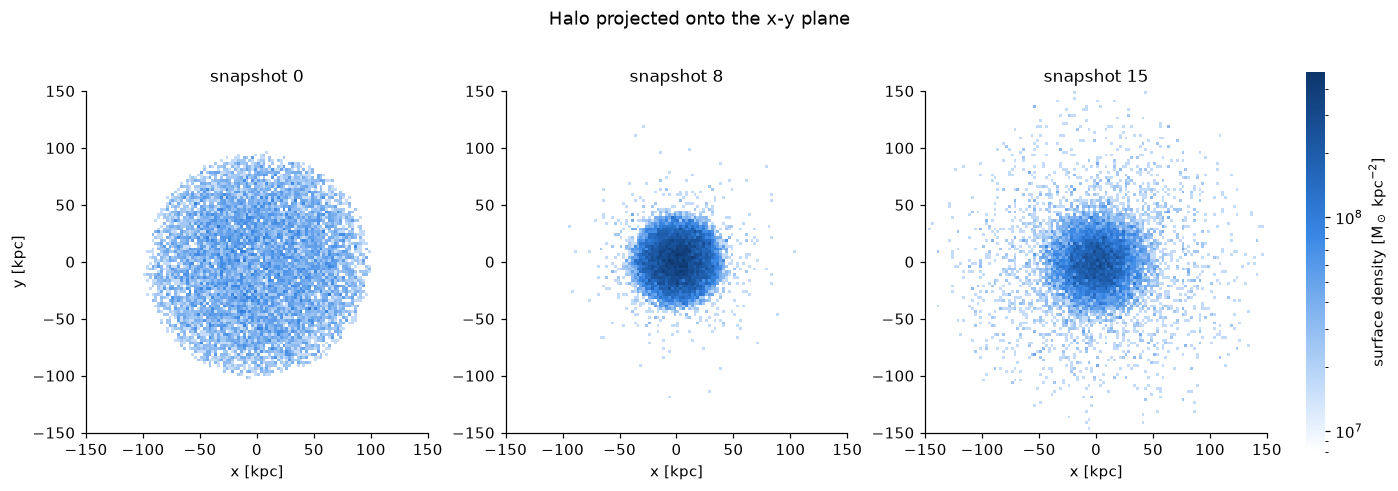

In [11]:
picks = sorted(set([0, len(snaps) // 2, len(snaps) - 1]))
images = []
for i in picks:
    p, _, m = read_snapshot(snaps[i])
    images.append(projection_image(p, m, find_center(p, m), extent, pixels))
vmin = mass0.min() / (2 * extent / pixels) ** 2   # one particle in a pixel
vmax = max(img.max() for img in images)

fig, axes = plt.subplots(1, len(picks), figsize=(4.2 * len(picks), 4.4), constrained_layout=True)
axes = np.atleast_1d(axes)
for ax, img, i in zip(axes, images, picks):
    im = ax.imshow(np.ma.masked_less_equal(img, 0), origin="lower", extent=[-extent, extent, -extent, extent],
                   cmap=density_cmap, norm=LogNorm(vmin=vmin, vmax=vmax), interpolation="nearest")
    ax.set_title(label(i))
    ax.set_xlabel("x [kpc]")
    ax.grid(False)
    ax.set_aspect("equal")
axes[0].set_ylabel("y [kpc]")
cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.02)
cb.set_label(r"surface density [M$_\odot$ kpc$^{-2}$]")
cb.outline.set_visible(False)
fig.suptitle("Halo projected onto the x-y plane")
fig.savefig(os.path.join(outdir, "projections.png"), dpi=300)
print(f"saved {os.path.join(outdir, 'projections.png')}")
plt.show()

NFW fit (12.7-132.0 kpc): r_s = 5.91 kpc, rho_s = 2.016e+08 Msun/kpc^3, rms log10 residual = 0.138


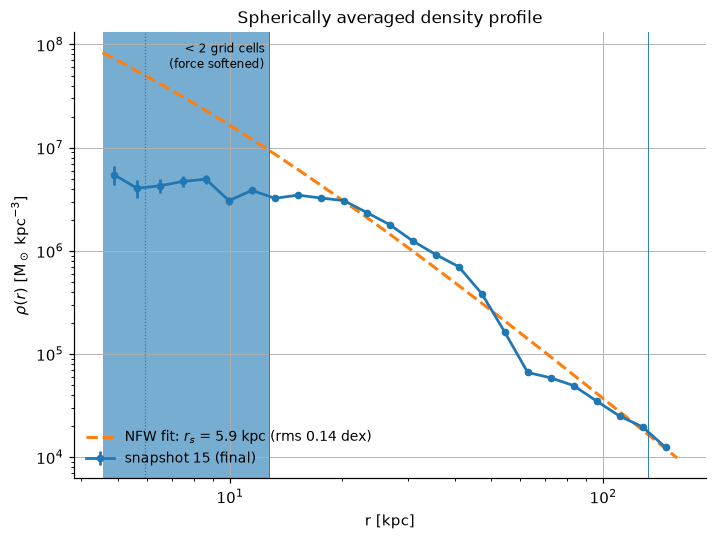

In [14]:
# Density Profile Fit: NFW

pos, _, mass = read_snapshot(snaps[-1])
r_last = np.linalg.norm(pos - find_center(pos, mass), axis=1)
edges = np.logspace(np.log10(max(0.5 * soft, np.percentile(r_last, 0.2))),
                    np.log10(np.percentile(r_last, 99)), nbins + 1)

fig, ax = plt.subplots(figsize=(6.4, 4.8), constrained_layout=True)

# earlier snapshots, light -> dark blue as time goes on
# earlier = np.unique(np.linspace(0, len(snaps) - 2, min(5, len(snaps) - 1)).astype(int)) if len(snaps) > 1 else []
# for j, i in enumerate(earlier):
#     p, _, m = read_snapshot(snaps[i])
#     r_mid, rho, _, n = density_profile(np.linalg.norm(p - find_center(p, m), axis=1), m, edges)
#     ok = n >= 5   # skip nearly empty (very noisy) bins
#     ax.plot(r_mid[ok], rho[ok], color=time_cmap(j / max(len(earlier), 1) * 0.75), lw=1.2, label=label(i))

# last snapshot with Poisson error bars
r_mid, rho, err, n = density_profile(r_last, mass, edges)
ok = n > 0
ax.errorbar(r_mid[ok], rho[ok], yerr=err[ok], lw=1.8, marker="o", ms=4, capsize=0,
            label=label(len(snaps) - 1) + " (final)")

# NFW fit to the last snapshot
fit_lo = fit_rmin if fit_rmin is not None else max(2.0 * soft, np.percentile(r_last, 1))
fit_hi = fit_rmax if fit_rmax is not None else np.percentile(r_last, 90)
fit = fit_nfw(r_mid, rho, n, fit_lo, fit_hi)
if fit is not None:
    rho_s, r_s, rms = fit
    rr = np.logspace(np.log10(edges[0]), np.log10(edges[-1]), 200)
    ax.plot(rr, nfw_density(rr, rho_s, r_s), lw=2, ls="--",
            label=fr"NFW fit: $r_s$ = {r_s:.1f} kpc (rms {rms:.2f} dex)")
    ax.axvline(r_s, lw=0.8, ls=":")
    ax.axvline(fit_lo, lw=0.6)
    ax.axvline(fit_hi, lw=0.6)
    print(f"NFW fit ({fit_lo:.1f}-{fit_hi:.1f} kpc): r_s = {r_s:.2f} kpc, "
          f"rho_s = {rho_s:.3e} Msun/kpc^3, rms log10 residual = {rms:.3f}")

ax.axvspan(edges[0], 2.0 * soft, alpha=0.6, lw=0)
ax.text(2.0 * soft, 0.98, "< 2 grid cells \n(force softened) ", transform=ax.get_xaxis_transform(), fontsize=8, ha="right", va="top")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("r [kpc]")
ax.set_ylabel(r"$\rho(r)$ [M$_\odot$ kpc$^{-3}$]")
ax.set_title("Spherically averaged density profile")
ax.legend(loc="lower left")
fig.savefig(os.path.join(outdir, "density_profile.png"), dpi=150)
plt.show()